# Compare three greedy policies across chronics

Agents involved in the comparison: 
- **greedy-agent (revert_thr=0.85, action_thr=0.95)**
- **greedy-agent (revert_thr=0)**
- **greedy-agent (action_thr=10)**
  
The original experiment sampled ten **chronics with one selection seed (42)**. 
We use both levels: **equal-weight episode summaries** for overall comparisons, and **individual chronic/event plots** to expose failures and rare decisions.

In [95]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "agent.py").exists() and (ROOT.parent / "agent.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "agent.py").exists():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from dataset_analysis import save_dataset, load_dataset, build_tables, paired_episode_means

DATA_DIR = ROOT / "data" / "irl_datasets"
FIG_DIR = ROOT / "artifacts" / "irl_analysis"
AGENTS = ["normal", "no_revert", "no_action"]
MARKERS = ["o", "s", "p"]
COLORS = dict(zip(AGENTS, ["#2878b5", "#e07b39", "#48945c"]))
POLICIES = {
    "normal": {"revert_thr": 0.85, "action_thr": 0.95},
    "no_revert": {"revert_thr": 0.0, "action_thr": 0.95},
    "no_action": {"revert_thr": 0.85, "action_thr": 10.0},
}
plt.rcParams.update({"figure.figsize": (11, 4), 
                     "axes.spines.top": False, 
                     "axes.spines.right": False, 
                     "axes.grid": True,
                     "grid.alpha": 0.3,
                     "grid.linestyle": '--'})

def finish_figure(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Dataset collection

Leave `RUN_COLLECTION = False` to skip data collection and load saved datasets.

In [2]:
RUN_COLLECTION = False
WITH_OPPONENT = False
N_EPISODES = 10
SELECTION_SEED = 42

if RUN_COLLECTION:
    import hashlib
    import grid2op
    from grid2op.Opponent import BaseOpponent
    from grid2op.Reward import (BridgeReward, CloseToOverflowReward, DistanceReward,
                               EconomicReward, EpisodeDurationReward, GameplayReward)
    from lightsim2grid import LightSimBackend
    from agent import GreedyAgent
    from dataset_analysis import action_dict

    other_rewards = dict(bridge=BridgeReward, closeToOverflow=CloseToOverflowReward,
                        distance=DistanceReward, economic=EconomicReward,
                        episodeDuration=EpisodeDurationReward, gameplay=GameplayReward)
    
    kwargs = dict(backend=LightSimBackend(), other_rewards=other_rewards)
    
    if not WITH_OPPONENT:
        kwargs["opponent_class"] = BaseOpponent
    env = grid2op.make("l2rpn_icaps_2021_large_train", **kwargs)
    
    try:
        available = list(env.chronics_handler.available_chronics())
        
        # Reproduce the legacy sampling rule; check duplicates before using it.
        selected = np.random.default_rng(SELECTION_SEED).choice(available, N_EPISODES)
        
        if len(set(selected)) != N_EPISODES:
            raise ValueError("Repeated chronics: choose a new plan without replacement.")
        
        plan = [{"chronic": Path(str(ch)).name, "env_seed": 1000 + i} for i, ch in enumerate(selected)]
        action_path = ROOT / "action_spaces/l2rpn_icaps_2021_large/top_actions_1000.json"
        filtered_actions = [env.action_space(a) for a in json.loads(action_path.read_text())]
        
        for name in AGENTS:
            path = DATA_DIR / f"{name}.jsonl.gz"
            if path.exists():
                existing, meta = load_dataset(path)
                if meta.get("collection_plan") != plan:
                    print(f"Keeping {name} archive with a different/legacy plan. Use a new DATA_DIR to recollect all policies.")
                    continue
                if meta.get("with_opponent") != WITH_OPPONENT or meta.get("policy") != POLICIES[name]:
                    raise ValueError("Archive configuration differs: use a new DATA_DIR.")
            else:
                existing = {}
            
            if existing:
                expected_hashes = {
                    "agent_sha256": hashlib.sha256((ROOT / "agent.py").read_bytes()).hexdigest(),
                    "actions_sha256": hashlib.sha256(action_path.read_bytes()).hexdigest(),
                }
                if any(meta.get(k) != v for k, v in expected_hashes.items()):
                    raise ValueError("Agent code/action set changed: use a new DATA_DIR.")
                if meta.get("grid2op_version") != grid2op.__version__:
                    raise ValueError("Grid2Op version changed: use a new DATA_DIR.")
            
            agent = GreedyAgent(env.action_space, filtered_actions, **POLICIES[name], n_workers=8)
            meta = dict(agent=name, 
                        policy=POLICIES[name], 
                        collection_plan=plan,
                        selection_seed=SELECTION_SEED, 
                        with_opponent=WITH_OPPONENT,
                        environment=env.name, 
                        grid2op_version=grid2op.__version__,
                        reward_class=type(env.get_reward_instance()).__name__,
                        other_rewards={k: v.__name__ for k, v in other_rewards.items()},
                        agent_sha256=hashlib.sha256((ROOT / "agent.py").read_bytes()).hexdigest(),
                        actions_sha256=hashlib.sha256(action_path.read_bytes()).hexdigest())
            
            for i, (ch, item) in enumerate(zip(selected, plan)):
                if str(i) in existing:
                    continue
                env.set_id(str(ch))
                obs = env.reset(seed=item["env_seed"])
                agent.reset(obs)
                episode = dict(**item, observations=[], actions=[], rewards=[], infos=[], dones=[])
                
                done = False
                while not done:
                    action = agent.act(obs)
                    episode["observations"].append(obs.to_json())
                    episode["actions"].append(action_dict(action))
                    obs, reward, done, info = env.step(action)
                    episode["rewards"].append(float(reward))
                    episode["infos"].append(info)
                    episode["dones"].append(bool(done))
                
                episode["final_observation"] = obs.to_json()
                existing[str(i)] = episode
                save_dataset(existing, path, meta)
                print(name, item, "steps:", len(episode["actions"]))
            
            datasets[name], dataset_metadata[name] = load_dataset(path)
    finally:
        env.close()

In [3]:
datasets, dataset_metadata = {}, {}
for name in AGENTS:
    path = DATA_DIR / f"{name}.jsonl.gz"
    in_memory = globals().get(f"dataset_{name}")
    
    if in_memory is not None and not path.exists():
        metadata = {
            "agent": name, "policy": POLICIES[name], "selection_seed": 42,
            "provenance": "legacy notebook collection; reset seeds not recorded",
            "environment": "l2rpn_icaps_2021_large_train",
            "with_opponent": False,
        }
        save_dataset(in_memory, path, metadata)
        print(f"Saved {name}: {len(in_memory)} episodes to {path}")
    
    if path.exists():
        datasets[name], dataset_metadata[name] = load_dataset(path)
        print(f"Loaded {name}: {len(datasets[name])} episodes")
    else:
        print(f"Missing {name}: run this cell in the kernel holding dataset_{name}, "
              "or enable collection below.")

Loaded normal: 10 episodes
Loaded no_revert: 10 episodes
Loaded no_action: 10 episodes


## Construct transition tables

Each row uses `state[t]`, `requested_action[t]`, `reward[t]`, `info[t]`, and the actual `state[t+1]`. Reject terminal-like/nonfinite electrical states from loading-change calculations; never interpret terminal zeros as congestion relief. `flagged_actions` includes illegal, ambiguous, failed redispatch and illegal reconnection, without assuming every flag replaces the whole action.

Action labels describe requests: topology, line status, combined/other, or explicit no-op. An assignment to an already occupied bus can be electrically redundant but is still a request. `requests_bus1_only` is descriptive and does not prove a reversion branch was used.

In [10]:
missing = set(AGENTS) - set(datasets)
assert len(AGENTS) == len(datasets), "Some datasets is missing "

transitions, episodes = build_tables(datasets, selected_episodes=None)
if transitions.empty:
    raise ValueError("Datasets contain no transitions.")
if episodes.duplicated(["agent", "pair_id"]).any():
    raise ValueError("Repeated chronic/seed pairs: inspect duplicates before paired comparison.")

coverage = episodes.pivot(index="pair_id", columns="agent", values="steps")
coverage

agent,no_action,no_revert,normal
pair_id,,,
Scenario_august_023|seed=unknown,8062,8062,8062
Scenario_august_036|seed=unknown,8062,8062,8062
Scenario_august_053|seed=unknown,8062,8062,8062
Scenario_december_157|seed=unknown,1005,8062,8062
Scenario_july_022|seed=unknown,8062,8062,8062
Scenario_july_055|seed=unknown,8062,8062,8062
Scenario_march_222|seed=unknown,8062,8062,8062
Scenario_may_130|seed=unknown,8062,8062,8062
Scenario_november_067|seed=unknown,141,8062,8062


In [28]:
datasets['no_action']['1']['chronic']

'Scenario_november_067'

In [35]:
datasets['no_action']['1']['infos'][-1].keys()

dict_keys(['disc_lines', 'is_illegal', 'is_ambiguous', 'failed_redispatching', 'is_illegal_reco', 'reason_alarm_illegal', 'reason_alert_illegal', 'opponent_attack_line', 'opponent_attack_sub', 'opponent_attack_duration', 'exception', 'time_series_id', 'rewards'])

In [29]:
for i in range(len(datasets['no_action']['1']['infos'])):
    exception = datasets['no_action']['1']['infos'][i]['exception']
    if exception: print(i, exception)

140 [{'exception_type': 'BackendError', 'message': 'Grid2OpException BackendError "Divergence of DC powerflow (non connected grid) at the initialization of AC powerflow. Detailed error: ErrorType.NotInitError"'}]


In [30]:
common_pairs = coverage.dropna().index
assert len(common_pairs) > 0, "No matched chronics pairs."

T = transitions[transitions.pair_id.isin(common_pairs)].copy()
E = episodes[episodes.pair_id.isin(common_pairs)].copy()
reward_cols = [c for c in T if c == "reward" or c.startswith("reward_")]

In [41]:
transitions.keys()

Index(['agent', 'episode_id', 'chronic', 'env_seed', 'pair_id', 't', 'step',
       'hours', 'reward', 'done', 'next_state_available', 'next_max_rho',
       'max_rho', 'overloaded', 'disconnected', 'bus2', 'load_mw',
       'generation_mw', 'valid', 'action_type', 'active_action',
       'requested_components', 'requested_bus_changes', 'requests_bus1_only',
       'flagged_action', 'is_illegal', 'is_ambiguous', 'delta_rho',
       'reward_bridge', 'reward_closeToOverflow', 'reward_distance',
       'reward_economic', 'reward_episodeDuration', 'reward_gameplay'],
      dtype='object')

In [47]:
transitions.head()

,agent,episode_id,chronic,env_seed,pair_id,t,step,hours,reward,done,...,flagged_action,is_illegal,is_ambiguous,delta_rho,reward_bridge,reward_closeToOverflow,reward_distance,reward_economic,reward_episodeDuration,reward_gameplay
0,normal,0,Scenario_august_036,None,Scenario_august_036|seed=unknown,0,0.0,0.000000,0.0,None,...,False,False,False,-0.002229,0.0,1.0,1.0,0.735397,0.0,1.0
1,normal,0,Scenario_august_036,None,Scenario_august_036|seed=unknown,1,1.0,0.083333,0.0,None,...,False,False,False,-0.008188,0.0,1.0,1.0,0.735195,0.0,1.0
2,normal,0,Scenario_august_036,None,Scenario_august_036|seed=unknown,2,2.0,0.166667,0.0,None,...,False,False,False,-0.002733,0.0,1.0,1.0,0.735493,0.0,1.0
3,normal,0,Scenario_august_036,None,Scenario_august_036|seed=unknown,3,3.0,0.250000,0.0,None,...,False,False,False,-0.003682,0.0,1.0,1.0,0.735171,0.0,1.0
4,normal,0,Scenario_august_036,None,Scenario_august_036|seed=unknown,4,4.0,0.333333,0.0,None,...,False,False,False,-0.002774,0.0,1.0,1.0,0.735655,0.0,1.0


In [135]:
T.groupby("agent").agg(transitions=("t", "size"), 
                       invalid_states=("valid", lambda x: (~x).sum()), 
                       missing_next_states=("next_state_available", lambda x: (~x).sum()),
                       flagged_actions=("flagged_action", "sum"))

,transitions,invalid_states,missing_next_states,flagged_actions
agent,,,,
no_action,57733,0,10,0
no_revert,80620,0,10,0
normal,80620,0,10,0


In [44]:
E.keys()

Index(['agent', 'episode_id', 'chronic', 'env_seed', 'pair_id', 'steps',
       'horizon', 'observed_horizon_fraction', 'terminal_recorded',
       'final_state_available', 'mean_max_rho', 'overload_fraction',
       'action_rate', 'flagged_action_rate', 'action_count', 'reward_mean',
       'reward_sum', 'reward_last', 'reward_bridge_mean', 'reward_bridge_sum',
       'reward_bridge_last', 'reward_closeToOverflow_mean',
       'reward_closeToOverflow_sum', 'reward_closeToOverflow_last',
       'reward_distance_mean', 'reward_distance_sum', 'reward_distance_last',
       'reward_economic_mean', 'reward_economic_sum', 'reward_economic_last',
       'reward_episodeDuration_mean', 'reward_episodeDuration_sum',
       'reward_episodeDuration_last', 'reward_gameplay_mean',
       'reward_gameplay_sum', 'reward_gameplay_last'],
      dtype='object')

In [84]:
E[["agent", "chronic", "action_count", "reward_distance_mean", "reward_distance_sum", "reward_economic_mean", "reward_economic_sum", 'reward_closeToOverflow_mean',
       'reward_closeToOverflow_sum']].head()

,agent,chronic,action_count,reward_distance_mean,reward_distance_sum,reward_economic_mean,reward_economic_sum,reward_closeToOverflow_mean,reward_closeToOverflow_sum
0,normal,Scenario_august_036,33,0.997671,8043.225989,0.778102,6273.056145,0.999578,8058.6
1,normal,Scenario_november_067,116,0.984634,7938.118644,0.618237,4984.225662,0.998214,8047.6
2,normal,Scenario_march_222,56,0.992661,8002.830508,0.714338,5758.992774,0.999082,8054.6
3,normal,Scenario_july_055,60,0.997038,8038.124294,0.803254,6475.833378,0.999231,8055.8
4,normal,Scenario_july_022,82,0.995660,8027.011299,0.802584,6470.429668,0.999032,8054.2


In [71]:
E.sort_values('action_rate', ascending=False)[["agent", "chronic", "steps", "horizon", "action_count", "action_rate", "reward_sum", "overload_fraction"]]

,agent,chronic,steps,horizon,action_count,action_rate,reward_sum,overload_fraction
14,no_revert,Scenario_july_022,8062,8062.0,276,0.034235,1.0,0.000248
11,no_revert,Scenario_november_067,8062,8062.0,122,0.015133,1.0,0.001613
8,normal,Scenario_december_157,8062,8062.0,121,0.015009,1.0,0.000372
18,no_revert,Scenario_december_157,8062,8062.0,120,0.014885,1.0,0.001861
1,normal,Scenario_november_067,8062,8062.0,116,0.014388,1.0,0.000496
4,normal,Scenario_july_022,8062,8062.0,82,0.010171,1.0,0.000372
16,no_revert,Scenario_august_023,8062,8062.0,68,0.008435,1.0,0.000496
3,normal,Scenario_july_055,8062,8062.0,60,0.007442,1.0,0.000620
2,normal,Scenario_march_222,8062,8062.0,56,0.006946,1.0,0.000496
7,normal,Scenario_may_130,8062,8062.0,56,0.006946,1.0,0.000000


In [131]:
T.groupby("agent")[reward_cols].count().rename_axis(columns="nonmissing reward counts")

nonmissing reward counts,reward,reward_bridge,reward_closeToOverflow,reward_distance,reward_economic,reward_episodeDuration,reward_gameplay
agent,,,,,,,
no_action,57733,57733,57733,57733,57733,57733,57733
no_revert,80620,80620,80620,80620,80620,80620,80620
normal,80620,80620,80620,80620,80620,80620,80620


## Analysis of behavior

Dots show individual episodes. Connecting lines pair the same chronic/reset seed across agents. Survival length is shown alongside loading and reward because early termination can make mean loading misleadingly low. `observed_horizon_fraction` is a length ratio, not proof of successful completion.

The summary uses an episode-level paired bootstrap (95% descriptive intervals). It resamples episodes, not autocorrelated timesteps. 

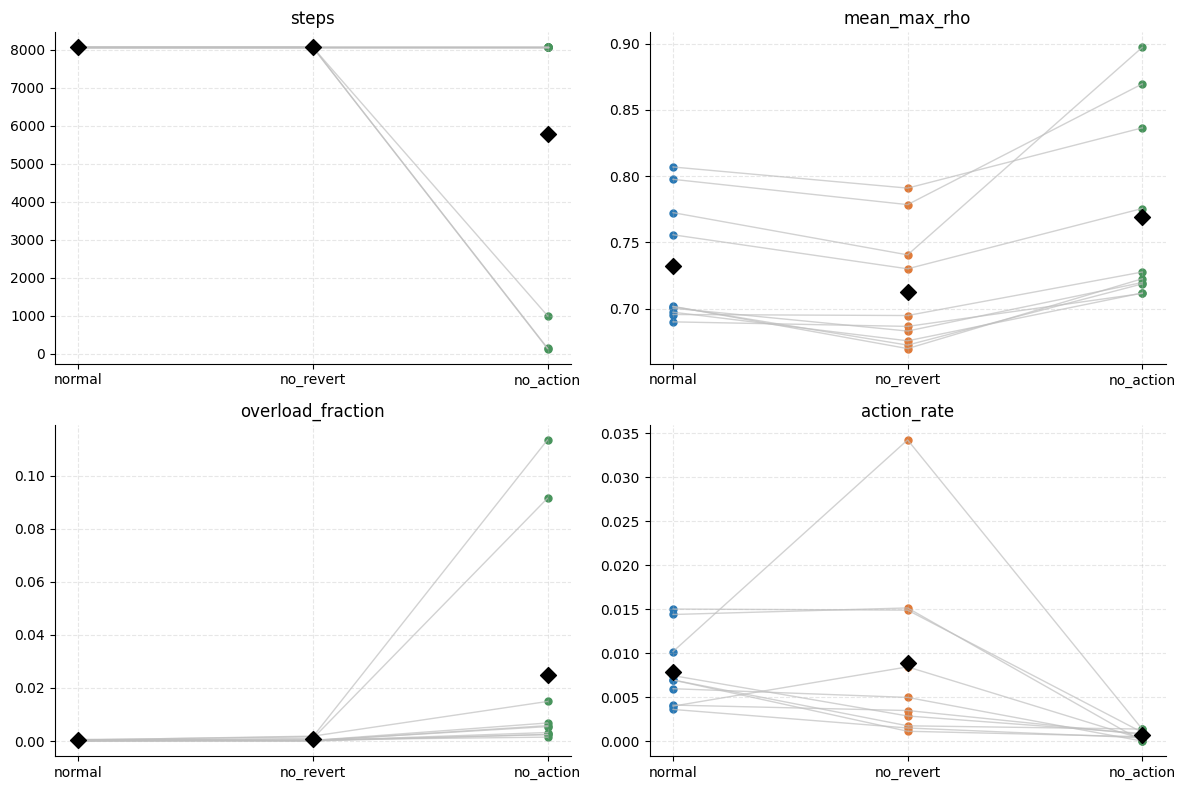

In [70]:
metrics = ["steps", "mean_max_rho", "overload_fraction", "action_rate"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(axes.flat, metrics):
    wide = E.pivot(index="pair_id", columns="agent", values=metric).reindex(columns=AGENTS)
    
    for _, row in wide.iterrows():
        ax.plot(range(len(AGENTS)), row, color="0.75", lw=1, alpha=.7)
    
    for i, agent in enumerate(AGENTS):
        ax.scatter(np.full(len(wide), i), wide[agent], color=COLORS[agent], s=25)
        ax.scatter(i, wide[agent].mean(), color="black", marker="D", s=65, zorder=3)

    ax.set(xticks=range(len(AGENTS)), xticklabels=AGENTS, title=metric)

finish_figure(fig, "episode_comparison")

In [62]:
summary = paired_episode_means(E, metrics + ["flagged_action_rate"])
summary.round(4)

,metric,agent,n_pairs,mean,low,high
0,steps,normal,10,8062.0000,8062.0000,8062.0000
1,steps,no_revert,10,8062.0000,8062.0000,8062.0000
2,steps,no_action,10,5773.3000,3484.5700,8062.0000
3,mean_max_rho,normal,10,0.7320,0.7063,0.7600
4,mean_max_rho,no_revert,10,0.7123,0.6882,0.7405
5,mean_max_rho,no_action,10,0.7691,0.7299,0.8114
6,overload_fraction,normal,10,0.0003,0.0002,0.0004
7,overload_fraction,no_revert,10,0.0006,0.0002,0.0010
8,overload_fraction,no_action,10,0.0248,0.0043,0.0533
9,action_rate,normal,10,0.0079,0.0056,0.0104


## State vs. action

Rates below are computed separately within each episode/loading bin, then averaged across episodes containing that bin. Missing bins remain missing, not zero. Counts show how much evidence supports each rate. A threshold of 0.95 explains the search branch, but reconnection can occur at other loadings.

An action’s association with a stressed state is not evidence that the action caused the stress.

In [87]:
bins = [-np.inf, .70, .85, .95, 1.0, 1.1, np.inf]
labels = ["<0.70", "0.70–0.85", "0.85–0.95", "0.95–1.00", "1.00–1.10", "≥1.10"]

T["rho_bin"] = pd.cut(T.max_rho, bins=bins, labels=labels, right=False)

state_rates = T[T.valid].groupby(["agent", "pair_id", "rho_bin"], observed=True).agg(
    rate=("active_action", "mean"), n=("t", "size")).reset_index()
state_summary = state_rates.groupby(["agent", "rho_bin"], observed=True).agg(
    mean_action_rate=("rate", "mean"), contributing_episodes=("rate", "size"), transitions=("n", "sum"))

state_summary

mean_action_rate  contributing_episodes  transitions
agent     rho_bin                                                        
no_action <0.70              0.000854                      8        28666
          0.70–0.85          0.000368                     10        20740
          0.85–0.95          0.000434                     10         6937
          0.95–1.00          0.000000                     10         1121
          1.00–1.10          0.000000                     10          246
          ≥1.10              0.000000                      6           23
no_revert <0.70              0.002469                     10        41853
          0.70–0.85          0.007808                     10        32791
          0.85–0.95          0.010567                     10         5625
          0.95–1.00          1.000000                     10          303
          1.00–1.10          1.000000                      8           43
          ≥1.10              1.000000                      3            5
normal    <0.70              0.003329                     10        35352
          0.70–0.85          0.004963                     10        35501
          0.85–0.95          0.000514                     10         9446
          0.95–1.00          1.000000                     10          298
          1.00–1.10          1.000000                      8           21
          ≥1.10              1.000000                      1            2

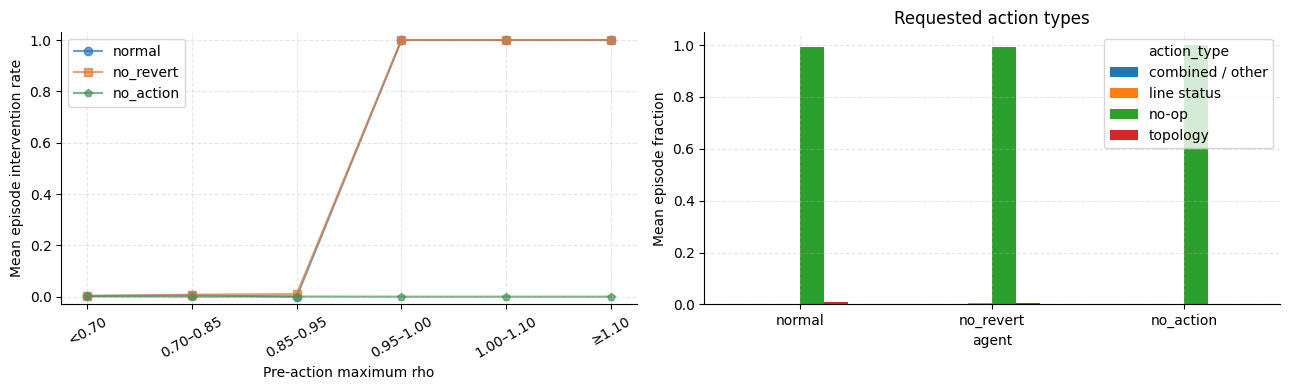

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for i, agent in enumerate(AGENTS):
    values = state_summary.loc[agent, "mean_action_rate"].reindex(labels)
    axes[0].plot(labels, values, label=agent, color=COLORS[agent], marker=MARKERS[i], alpha=0.7)

axes[0].set(xlabel="Pre-action maximum rho", ylabel="Mean episode intervention rate", ylim=(-.03, 1.03))
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()

counts = T.groupby(["agent", "pair_id", "action_type"]).size().unstack(fill_value=0)
fractions = counts.div(counts.sum(axis=1), axis=0).groupby("agent").mean().reindex(AGENTS)
fractions.plot.bar(stacked=False, ax=axes[1], rot=0)
axes[1].set(ylabel="Mean episode fraction", title="Requested action types")
finish_figure(fig, "state_action")

## Action vs. reward and next-state loading

For dense rewards compare episode means; for sparse rewards also inspect last values and returns. Main `AlarmReward` and `EpisodeDurationReward` are usually terminal, so averaging them over timesteps obscures their meaning. Returns depend on episode length. aReward scales are different and are not summed together.

Action-conditioned means are first calculated within episode/action type. No-op dominates the dataset; the tables expose sample counts. These are associations, not causal action effects: policies choose different actions in different states. Stratify by pre-action loading as well.

In [104]:
reward_overview = E[["agent", "chronic", "steps"] + [c + suffix for c in reward_cols for suffix in ["_mean", "_sum", "_last"]]]
reward_overview.round(4)

,agent,chronic,steps,reward_mean,reward_sum,reward_last,reward_bridge_mean,reward_bridge_sum,reward_bridge_last,reward_closeToOverflow_mean,...,reward_distance_last,reward_economic_mean,reward_economic_sum,reward_economic_last,reward_episodeDuration_mean,reward_episodeDuration_sum,reward_episodeDuration_last,reward_gameplay_mean,reward_gameplay_sum,reward_gameplay_last
0,normal,Scenario_august_036,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9996,...,1.0000,0.7781,6273.0561,0.7503,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
1,normal,Scenario_november_067,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9982,...,1.0000,0.6182,4984.2257,0.5721,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
2,normal,Scenario_march_222,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9991,...,1.0000,0.7143,5758.9928,0.6263,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
3,normal,Scenario_july_055,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9992,...,1.0000,0.8033,6475.8334,0.7663,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
4,normal,Scenario_july_022,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9990,...,0.9831,0.8026,6470.4297,0.7532,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
5,normal,Scenario_october_058,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9993,...,1.0000,0.6834,5509.5858,0.7482,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
6,normal,Scenario_august_023,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9996,...,1.0000,0.7794,6283.6864,0.7509,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
7,normal,Scenario_may_130,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9996,...,1.0000,0.7729,6230.9616,0.7172,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
8,normal,Scenario_december_157,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9982,...,1.0000,0.5476,4414.6322,0.4482,0.0001,1.0000,1.0000,1.0000,8062.0,1.0
9,normal,Scenario_august_053,8062,0.0001,1.0,1.0,0.0,0.0,0.0,0.9996,...,1.0000,0.7772,6265.4687,0.7524,0.0001,1.0000,1.0000,1.0000,8062.0,1.0


In [106]:
per_episode_action = T.groupby(["agent", "pair_id", "action_type"])[reward_cols].mean()
action_rewards = per_episode_action.groupby(["agent", "action_type"]).mean()
action_counts = T.groupby(["agent", "action_type"]).agg(transitions=("t", "size"), episodes=("pair_id", "nunique"))
action_rewards.join(action_counts).round(4)

reward  reward_bridge  reward_closeToOverflow  \
agent     action_type                                                       
no_action line status       0.0000            0.0                  0.8605   
          no-op            -0.0014            0.0                  0.9841   
no_revert combined / other  0.0000            0.0                  1.0000   
          line status       0.0000            0.0                  0.9990   
          no-op             0.0001            0.0                  0.9991   
          topology          0.0000            0.0                  0.9954   
normal    line status       0.0000            0.0                  1.0000   
          no-op             0.0001            0.0                  0.9992   
          topology          0.0000            0.0                  0.9988   

                            reward_distance  reward_economic  \
agent     action_type                                          
no_action line status                1.0000           0.7644   
          no-op                      0.9980           0.7282   
no_revert combined / other           0.9209           0.7770   
          line status                0.9099           0.6988   
          no-op                      0.9352           0.7272   
          topology                   0.9332           0.7149   
normal    line status                0.9871           0.7542   
          no-op                      0.9940           0.7278   
          topology                   0.9786           0.7231   

                            reward_episodeDuration  reward_gameplay  \
agent     action_type                                                 
no_action line status                       0.0000           1.0000   
          no-op                             0.0001           0.9971   
no_revert combined / other                  0.0000           1.0000   
          line status                       0.0000           1.0000   
          no-op                             0.0001           1.0000   
          topology                          0.0000           1.0000   
normal    line status                       0.0000           1.0000   
          no-op                             0.0001           1.0000   
          topology                          0.0000           1.0000   

                            transitions  episodes  
agent     action_type                              
no_action line status                45         8  
          no-op                   57688        10  
no_revert combined / other            4         2  
          line status               361         5  
          no-op                   79908        10  
          topology                  347        10  
normal    line status                37         4  
          no-op                   79987        10  
          topology                  596        10

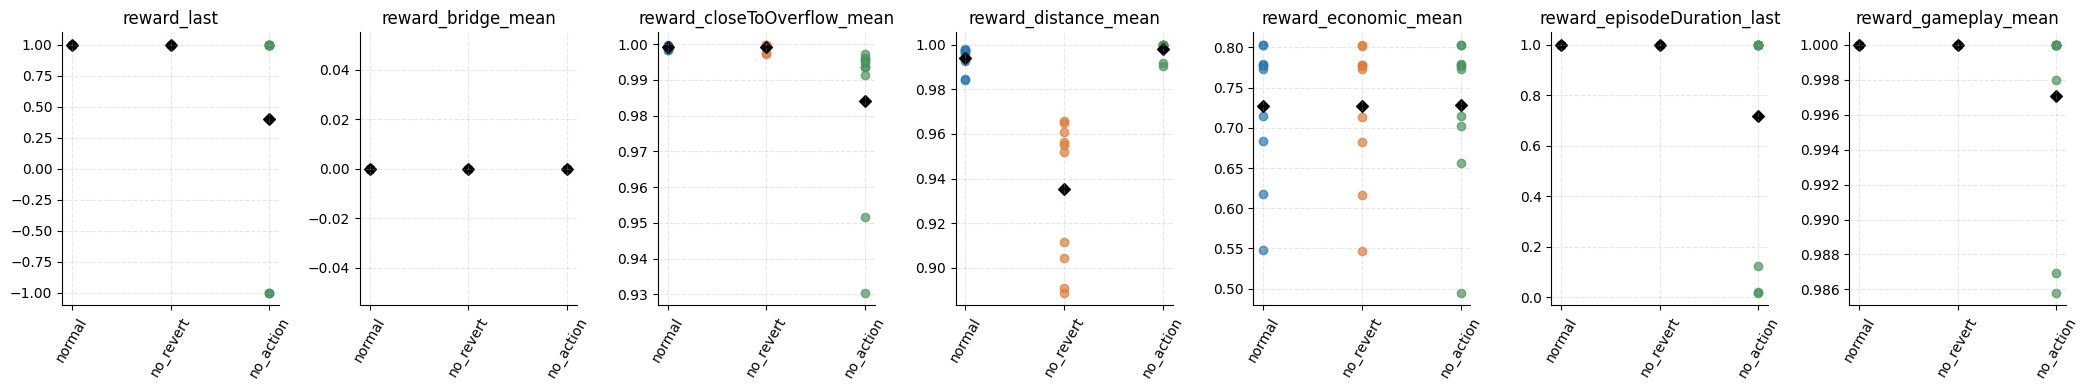

In [116]:
fig, axes = plt.subplots(1, len(reward_cols), figsize=(max(10, 3*len(reward_cols)), 4), squeeze=False)

for ax, col in zip(axes.flat, reward_cols):
    terminal_metric = col in ["reward", "reward_episodeDuration"]
    suffix = "_last" if terminal_metric else "_mean"
    wide = E.pivot(index="pair_id", columns="agent", values=col+suffix).reindex(columns=AGENTS)
    
    for i, a in enumerate(AGENTS):
        ax.scatter(np.full(len(wide), i), wide[a], color=COLORS[a], alpha=.7)
        ax.scatter(i, wide[a].mean(), marker="D", color="black")
    
    ax.set(xticks=range(3), xticklabels=AGENTS, title=col + suffix)
    ax.tick_params(axis="x", rotation=60)

finish_figure(fig, "reward_comparison")

In [109]:
outcome_rows = T[T.delta_rho.notna() & ~T.flagged_action].copy()
outcome_by_episode = outcome_rows.groupby(["agent", "pair_id", "action_type", "rho_bin"], observed=True).agg(
    mean_delta_rho=("delta_rho", "mean"), n=("t", "size"))
outcome_summary = outcome_by_episode.groupby(["agent", "action_type", "rho_bin"], observed=True).agg(
    mean_delta_rho=("mean_delta_rho", "mean"), contributing_episodes=("n", "size"), transitions=("n", "sum"))
outcome_summary.round(4)

mean_delta_rho  contributing_episodes  \
agent     action_type      rho_bin                                            
no_action line status      <0.70              0.2428                      6   
                           0.70–0.85          0.1931                      4   
                           0.85–0.95          0.0719                      2   
          no-op            <0.70              0.0022                      8   
                           0.70–0.85         -0.0006                     10   
                           0.85–0.95         -0.0010                     10   
                           0.95–1.00         -0.0037                     10   
                           1.00–1.10         -0.0297                     10   
                           ≥1.10             -0.0881                      6   
no_revert combined / other 0.95–1.00         -0.3032                      2   
                           1.00–1.10         -0.2116                      1   
          line status      <0.70              0.0030                      4   
                           0.70–0.85          0.0075                      5   
                           0.85–0.95          0.0073                      5   
          no-op            <0.70              0.0019                     10   
                           0.70–0.85         -0.0002                     10   
                           0.85–0.95          0.0004                     10   
          topology         0.95–1.00         -0.2659                     10   
                           1.00–1.10         -0.3105                      8   
                           ≥1.10             -0.4022                      3   
normal    line status      <0.70             -0.0082                      4   
                           0.70–0.85          0.0039                      2   
                           0.85–0.95          0.0102                      2   
          no-op            <0.70              0.0024                     10   
                           0.70–0.85         -0.0002                     10   
                           0.85–0.95         -0.0003                     10   
          topology         <0.70             -0.0058                     10   
                           0.70–0.85         -0.0438                     10   
                           0.95–1.00         -0.2695                     10   
                           1.00–1.10         -0.2996                      8   
                           ≥1.10             -0.2355                      1   

                                      transitions  
agent     action_type      rho_bin                 
no_action line status      <0.70               30  
                           0.70–0.85            9  
                           0.85–0.95            6  
          no-op            <0.70            28634  
                           0.70–0.85        20729  
                           0.85–0.95         6928  
                           0.95–1.00         1121  
                           1.00–1.10          245  
                           ≥1.10               21  
no_revert combined / other 0.95–1.00            3  
                           1.00–1.10            1  
          line status      <0.70              121  
                           0.70–0.85          201  
                           0.85–0.95           39  
          no-op            <0.70            41726  
                           0.70–0.85        32587  
                           0.85–0.95         5585  
          topology         0.95–1.00          300  
                           1.00–1.10           42  
                           ≥1.10                5  
normal    line status      <0.70               20  
                           0.70–0.85           14  
                           0.85–0.95            3  
          no-op            <0.70            35233  
                           0.70–0.85        35303  
                          

In [111]:
stratified_rewards = T.groupby(["agent", "pair_id", "action_type", "rho_bin"], observed=True)[reward_cols].mean()
stratified_rewards.groupby(["agent", "action_type", "rho_bin"], observed=True).mean().round(4)

reward  reward_bridge  \
agent     action_type      rho_bin                            
no_action line status      <0.70      0.0000            0.0   
                           0.70–0.85  0.0000            0.0   
                           0.85–0.95  0.0000            0.0   
          no-op            <0.70      0.0001            0.0   
                           0.70–0.85  0.0001            0.0   
                           0.85–0.95  0.0003            0.0   
                           0.95–1.00  0.0000            0.0   
                           1.00–1.10 -0.0062            0.0   
                           ≥1.10     -0.0889            0.0   
no_revert combined / other 0.95–1.00  0.0000            0.0   
                           1.00–1.10  0.0000            0.0   
          line status      <0.70      0.0000            0.0   
                           0.70–0.85  0.0000            0.0   
                           0.85–0.95  0.0000            0.0   
          no-op            <0.70      0.0001            0.0   
                           0.70–0.85  0.0001            0.0   
                           0.85–0.95  0.0002            0.0   
          topology         0.95–1.00  0.0000            0.0   
                           1.00–1.10  0.0000            0.0   
                           ≥1.10      0.0000            0.0   
normal    line status      <0.70      0.0000            0.0   
                           0.70–0.85  0.0000            0.0   
                           0.85–0.95  0.0000            0.0   
          no-op            <0.70      0.0001            0.0   
                           0.70–0.85  0.0001            0.0   
                           0.85–0.95  0.0002            0.0   
          topology         <0.70      0.0000            0.0   
                           0.70–0.85  0.0000            0.0   
                           0.95–1.00  0.0000            0.0   
                           1.00–1.10  0.0000            0.0   
                           ≥1.10      0.0000            0.0   

                                      reward_closeToOverflow  reward_distance  \
agent     action_type      rho_bin                                              
no_action line status      <0.70                      0.8711           1.0000   
                           0.70–0.85                  0.8500           1.0000   
                           0.85–0.95                  0.8800           1.0000   
          no-op            <0.70                      1.0000           0.9999   
                           0.70–0.85                  1.0000           0.9997   
                           0.85–0.95                  0.9893           0.9997   
                           0.95–1.00                  0.8352           0.9993   
                           1.00–1.10                  0.8108           0.9897   
                           ≥1.10                      0.7525           0.9044   
no_revert combined / other 0.95–1.00                  1.0000           0.9181   
                           1.00–1.10                  1.0000           0.9605   
          line status      <0.70                      1.0000           0.9257   
                           0.70–0.85                  0.9986           0.9080   
                           0.85–0.95                  0.9983           0.9108   
          no-op            <0.70                      1.0000           0.9358   
                           0.70–0.85                  0.9999           0.9348   
                           0.85–0.95                  0.9876           0.9409   
          topology         0.95–1.00                  0.9959           0.9324   
                           1.00–1.10                  0.9955           0.9288   
                           ≥1.10                      0.9667           0.9124   
normal    line status      <0.70                      1.0000           0.9852   
                           0.70–0.85                  1.0000           0.9854   
              

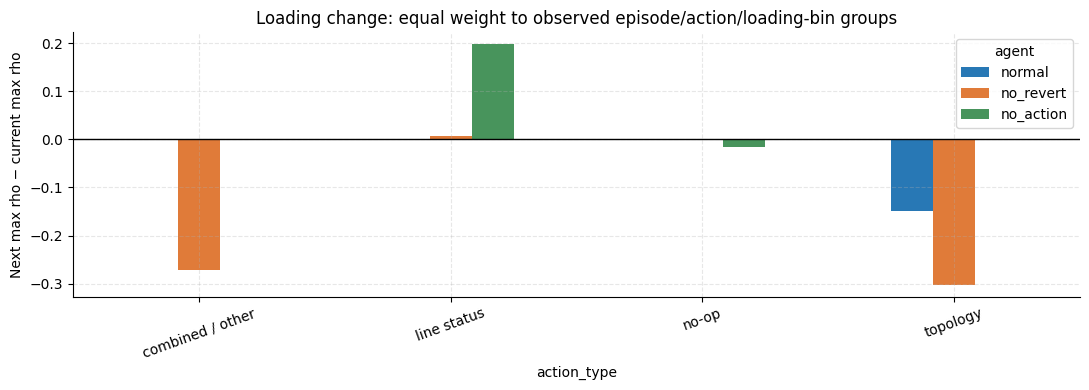

In [112]:
fig, ax = plt.subplots(figsize=(11, 4))

if not outcome_by_episode.empty:
    delta = outcome_by_episode.reset_index().groupby(["agent", "action_type"]).mean(numeric_only=True)["mean_delta_rho"].unstack("agent")
    delta.reindex(columns=AGENTS).plot.bar(ax=ax, color=[COLORS[a] for a in AGENTS], rot=20)

ax.axhline(0, color="black", lw=1)
ax.set(ylabel="Next max rho − current max rho", title="Loading change: equal weight to observed episode/action/loading-bin groups")
finish_figure(fig, "action_loading_change")

## Isolate informative chronics and inspect event windows

Rank chronics by disagreement in survival length, then action count. Timelines remain on absolute simulation time and stop when an episode ends; no zero-padding or averaging across unrelated dates. The common-prefix comparison uses only steps observed for all agents, and is supplementary to full-episode survival results.

Markers show requested interventions, crosses show flagged requests. The event table lists flagged actions, interventions and high-loading states. We can set `EVENT_STEP` to inspect a ±12-step window and keep the terminal context visible.

In [117]:
ranked = E.groupby("chronic").agg(
    survival_spread=("steps", lambda x: x.max()-x.min()),
    action_spread=("action_count", lambda x: x.max()-x.min()),
    worst_mean_loading=("mean_max_rho", "max")).sort_values(
        ["survival_spread", "action_spread", "worst_mean_loading"], ascending=False)
ranked

,survival_spread,action_spread,worst_mean_loading
chronic,,,
Scenario_november_067,7921,122,0.869665
Scenario_october_058,7909,48,0.897269
Scenario_december_157,7057,120,0.836511
Scenario_july_022,0,265,0.727670
Scenario_august_023,0,66,0.719749
Scenario_july_055,0,53,0.722547
Scenario_may_130,0,52,0.711472
Scenario_march_222,0,45,0.775620
Scenario_august_036,0,27,0.718680


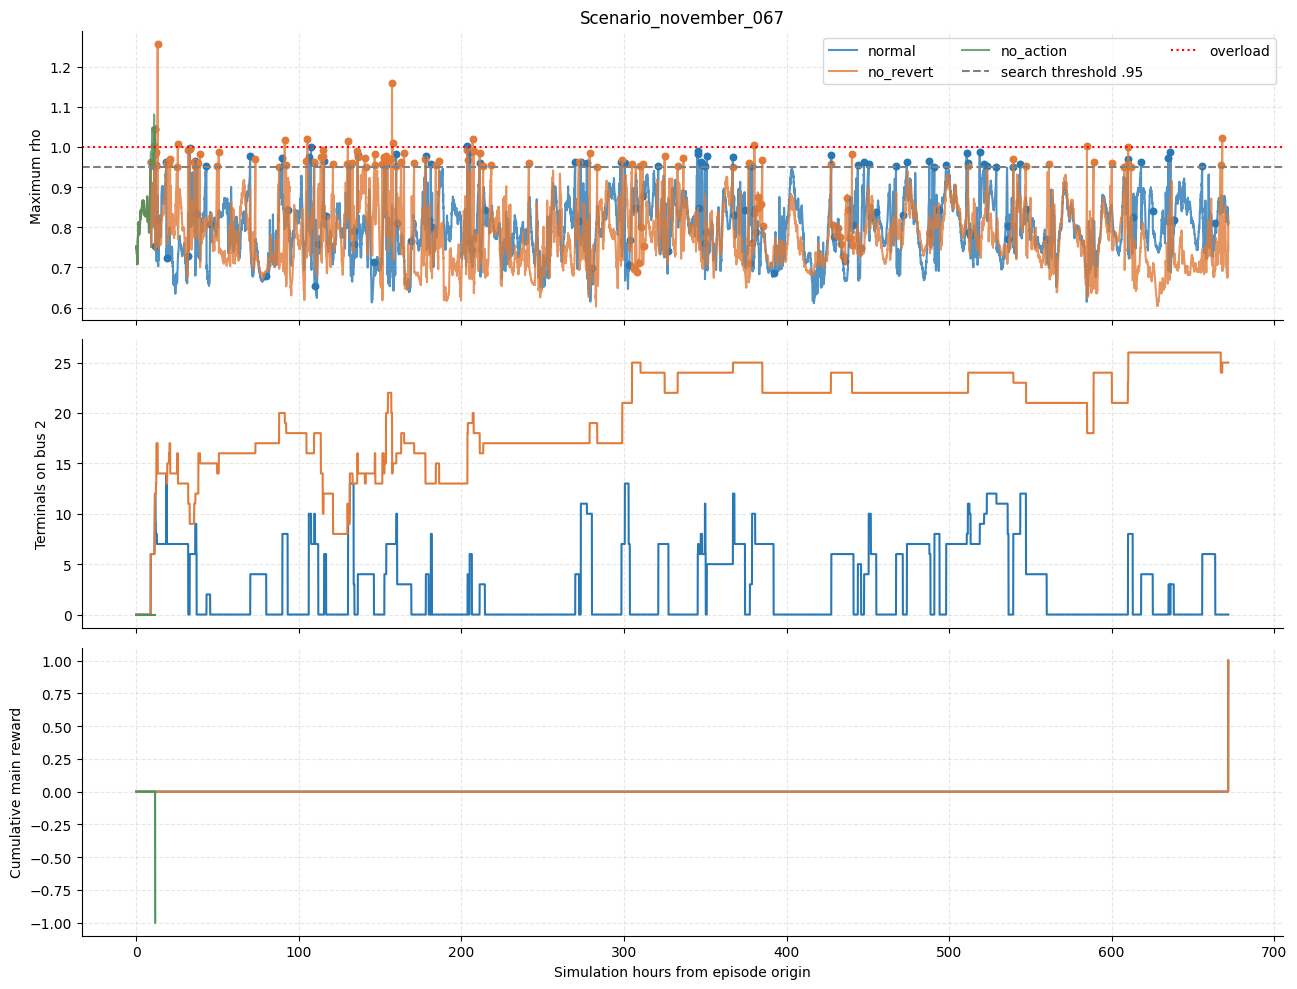

In [118]:
SELECTED_CHRONIC = None  # e.g. "Scenario_august_036"
selected = SELECTED_CHRONIC or ranked.index[0]
case = T[T.chronic == selected].copy()

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for agent in AGENTS:
    x = case[case.agent == agent]
    axes[0].plot(x.hours, x.max_rho, label=agent, color=COLORS[agent], alpha=.8)
    active = x[x.active_action]
    axes[0].scatter(active.hours, active.max_rho, color=COLORS[agent], s=22, marker="o")
    flagged = x[x.flagged_action]
    axes[0].scatter(flagged.hours, flagged.max_rho, color=COLORS[agent], s=70, marker="x")
    axes[1].plot(x.hours, x.bus2, color=COLORS[agent])
    axes[2].plot(x.hours, x.reward.cumsum(), color=COLORS[agent])

axes[0].axhline(.95, ls="--", color="0.5", label="search threshold .95")
axes[0].axhline(1, ls=":", color="red", label="overload")
axes[0].legend(ncol=3)
axes[0].set(ylabel="Maximum rho", title=selected)
axes[1].set(ylabel="Terminals on bus 2")
axes[2].set(ylabel="Cumulative main reward", xlabel="Simulation hours from episode origin")
finish_figure(fig, "selected_chronic")

In [119]:
prefix = T.groupby(["pair_id", "step"]).filter(lambda x: x.agent.nunique() == len(AGENTS))
prefix.groupby(["agent", "pair_id"]).agg(mean_max_rho=("max_rho", "mean"),
    action_rate=("active_action", "mean"), shared_steps=("step", "size"))

mean_max_rho  action_rate  \
agent     pair_id                                                         
no_action Scenario_august_023|seed=unknown        0.719749     0.000248   
          Scenario_august_036|seed=unknown        0.718680     0.000744   
          Scenario_august_053|seed=unknown        0.711857     0.000372   
          Scenario_december_157|seed=unknown      0.836511     0.000995   
          Scenario_july_022|seed=unknown          0.727670     0.001364   
          Scenario_july_055|seed=unknown          0.722547     0.000868   
          Scenario_march_222|seed=unknown         0.775620     0.001364   
          Scenario_may_130|seed=unknown           0.711472     0.000496   
          Scenario_november_067|seed=unknown      0.869665     0.000000   
          Scenario_october_058|seed=unknown       0.897269     0.000000   
no_revert Scenario_august_023|seed=unknown        0.683099     0.008435   
          Scenario_august_036|seed=unknown        0.672486     0.003473   
          Scenario_august_053|seed=unknown        0.675730     0.001488   
          Scenario_december_157|seed=unknown      0.806547     0.005970   
          Scenario_july_022|seed=unknown          0.694820     0.034235   
          Scenario_july_055|seed=unknown          0.669865     0.002853   
          Scenario_march_222|seed=unknown         0.730104     0.001737   
          Scenario_may_130|seed=unknown           0.686610     0.001116   
          Scenario_november_067|seed=unknown      0.832605     0.028369   
          Scenario_october_058|seed=unknown       0.819349     0.019608   
normal    Scenario_august_023|seed=unknown        0.700362     0.003969   
          Scenario_august_036|seed=unknown        0.701518     0.004093   
          Scenario_august_053|seed=unknown        0.697343     0.003597   
          Scenario_december_157|seed=unknown      0.821623     0.008955   
          Scenario_july_022|seed=unknown          0.695587     0.010171   
          Scenario_july_055|seed=unknown          0.701773     0.007442   
          Scenario_march_222|seed=unknown         0.755787     0.006946   
          Scenario_may_130|seed=unknown           0.690039     0.006946   
          Scenario_november_067|seed=unknown      0.832605     0.028369   
          Scenario_october_058|seed=unknown       0.832030     0.039216   

                                              shared_steps  
agent     pair_id                                           
no_action Scenario_august_023|seed=unknown            8062  
          Scenario_august_036|seed=unknown            8062  
          Scenario_august_053|seed=unknown            8062  
          Scenario_december_157|seed=unknown          1005  
          Scenario_july_022|seed=unknown              8062  
          Scenario_july_055|seed=unknown              8062  
          Scenario_march_222|seed=unknown             8062  
          Scenario_may_130|seed=unknown               8062  
          Scenario_november_067|seed=unknown           141  
          Scenario_october_058|seed=unknown            153  
no_revert Scenario_august_023|seed=unknown            8062  
          Scenario_august_036|seed=unknown            8062  
          Scenario_august_053|seed=unknown            8062  
          Scenario_december_157|seed=unknown          1005  
          Scenario_july_022|seed=unknown              8062  
          Scenario_july_055|seed=unknown              8062  
          Scenario_march_222|seed=unknown             8062  
          Scenario_may_130|seed=unknown               8062  
          Scenario_november_067|seed=unknown           141  
          Scenario_october_058|seed=unknown            153  
normal    Scenario_august_023|seed=unknown            8062  
          Scenario_august_036|seed=unknown            8062  
          Scenario_august_053|seed=unknown            8062  
          Scenario_december_157|seed=unknown          1005  
          Scenario_july_022|seed=unknown              8062 

In [122]:
case_events = case[case.active_action | case.flagged_action | (case.max_rho >= 1)].sort_values(
    ["flagged_action", "max_rho"], ascending=False)
event_columns = ["agent", "step", "max_rho", "action_type", "requested_bus_changes",
                 "requests_bus1_only", "flagged_action", "next_max_rho", "delta_rho"] + reward_cols
case_events[event_columns].head(40)

,agent,step,max_rho,action_type,requested_bus_changes,requests_bus1_only,flagged_action,next_max_rho,delta_rho,reward,reward_bridge,reward_closeToOverflow,reward_distance,reward_economic,reward_episodeDuration,reward_gameplay
88840,no_revert,158.0,1.255245,topology,3,True,False,0.772273,-0.482972,0.0,0.0,1.0,0.920904,0.273560,0.000000,1.0
90570,no_revert,1888.0,1.159177,topology,6,True,False,0.827281,-0.331896,0.0,0.0,1.0,0.920904,0.425496,0.000000,1.0
169434,no_action,132.0,1.080670,no-op,0,False,False,1.009824,-0.070846,0.0,0.0,0.8,0.977401,0.404651,0.000000,1.0
169433,no_action,131.0,1.066128,no-op,0,False,False,1.080670,0.014542,0.0,0.0,0.8,0.988701,0.409607,0.000000,1.0
169442,no_action,140.0,1.050781,no-op,0,False,False,NaN,NaN,-1.0,0.0,0.0,0.000000,0.000000,0.017489,-1.0
169441,no_action,139.0,1.050668,no-op,0,False,False,1.050781,0.000113,0.0,0.0,0.8,0.966102,0.362054,0.000000,1.0
169440,no_action,138.0,1.048980,no-op,0,False,False,1.050668,0.001688,0.0,0.0,0.8,0.966102,0.369427,0.000000,1.0
169420,no_action,118.0,1.047459,no-op,0,False,False,0.950453,-0.097006,0.0,0.0,0.8,0.988701,0.368503,0.000000,1.0
8197,normal,135.0,1.045382,topology,2,False,False,0.982562,-0.062820,0.0,0.0,0.8,0.949153,0.368293,0.000000,1.0
88817,no_revert,135.0,1.045382,topology,2,False,False,0.982562,-0.062820,0.0,0.0,0.8,0.949153,0.368293,0.000000,1.0


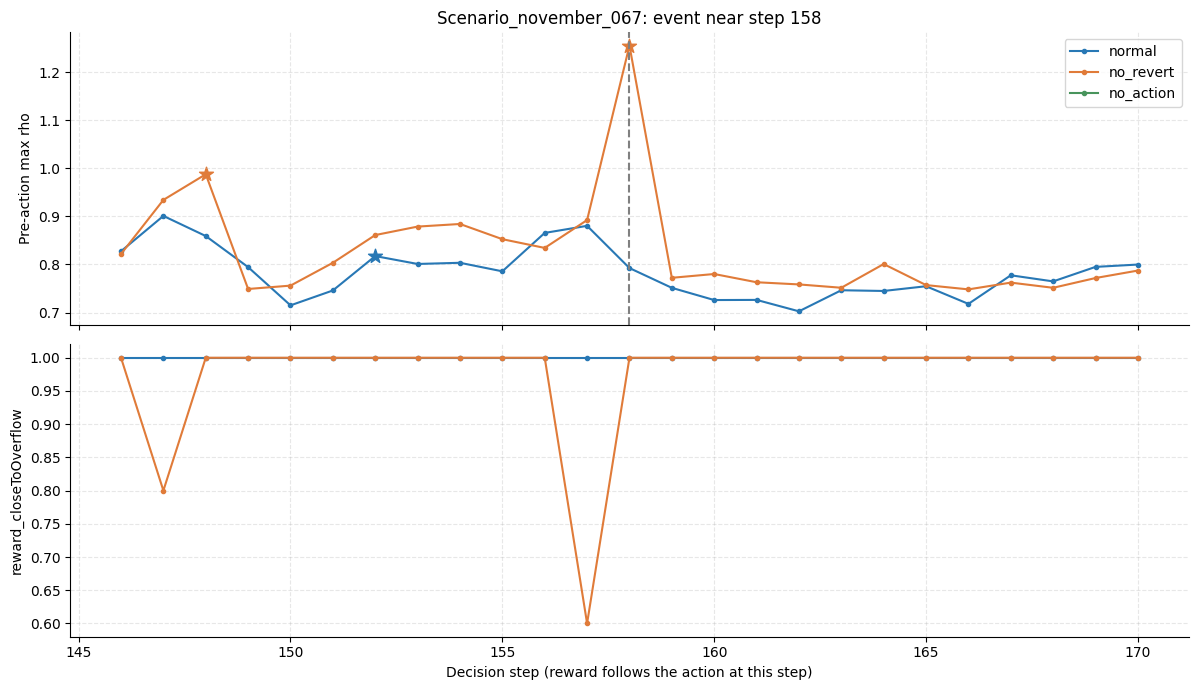

In [123]:
EVENT_STEP = None
center = EVENT_STEP if EVENT_STEP is not None else (case_events.iloc[0].step if len(case_events) else case.step.min())
window = case[case.step.between(center-12, center+12)]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
EVENT_REWARD = "reward_closeToOverflow" if "reward_closeToOverflow" in reward_cols else "reward"

for agent in AGENTS:
    x = window[window.agent == agent]
    axes[0].plot(x.step, x.max_rho, marker=".", label=agent, color=COLORS[agent])
    active = x[x.active_action]
    axes[0].scatter(active.step, active.max_rho, marker="*", s=110, color=COLORS[agent])
    axes[1].plot(x.step, x[EVENT_REWARD], marker=".", color=COLORS[agent])

axes[0].axvline(center, color="0.5", ls="--")
axes[0].set(ylabel="Pre-action max rho", title=f"{selected}: event near step {center:g}")
axes[0].legend()
axes[1].set(xlabel="Decision step (reward follows the action at this step)", ylabel=EVENT_REWARD)
finish_figure(fig, "event_window")

In [125]:
window[event_columns].sort_values(["step", "agent"])

,agent,step,max_rho,action_type,requested_bus_changes,requests_bus1_only,flagged_action,next_max_rho,delta_rho,reward,reward_bridge,reward_closeToOverflow,reward_distance,reward_economic,reward_episodeDuration,reward_gameplay
88828,no_revert,146.0,0.821799,no-op,0,False,False,0.934300,0.112501,0.0,0.0,1.0,0.926554,0.344116,0.0,1.0
8208,normal,146.0,0.827490,no-op,0,False,False,0.901000,0.073510,0.0,0.0,1.0,0.954802,0.344419,0.0,1.0
88829,no_revert,147.0,0.934300,no-op,0,False,False,0.987651,0.053351,0.0,0.0,0.8,0.926554,0.354711,0.0,1.0
8209,normal,147.0,0.901000,no-op,0,False,False,0.859170,-0.041830,0.0,0.0,1.0,0.954802,0.354998,0.0,1.0
88830,no_revert,148.0,0.987651,topology,4,False,False,0.749035,-0.238616,0.0,0.0,1.0,0.903955,0.346357,0.0,1.0
8210,normal,148.0,0.859170,no-op,0,False,False,0.794501,-0.064669,0.0,0.0,1.0,0.954802,0.346694,0.0,1.0
88831,no_revert,149.0,0.749035,no-op,0,False,False,0.756016,0.006981,0.0,0.0,1.0,0.903955,0.335437,0.0,1.0
8211,normal,149.0,0.794501,no-op,0,False,False,0.714955,-0.079547,0.0,0.0,1.0,0.954802,0.335787,0.0,1.0
88832,no_revert,150.0,0.756016,no-op,0,False,False,0.803509,0.047493,0.0,0.0,1.0,0.903955,0.321369,0.0,1.0
8212,normal,150.0,0.714955,no-op,0,False,False,0.745929,0.030974,0.0,0.0,1.0,0.954802,0.321893,0.0,1.0


## 8. Export analysis tables

Archives remain the source data. These CSVs contain derived summaries and transitions, and PNGs are saved under `artifacts/irl_analysis`. The calculations above can be rerun without simulating again.

Interpretation checklist: compare survival first; inspect individual paired chronics; compare interventions conditional on pre-action loading; keep terminal rewards separate from dense rewards; inspect flagged requests; treat next-step loading changes as observational rather than causal. Counterfactual evaluation would require simulating alternative actions from the same state.

In [ ]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
T.to_csv(FIG_DIR / "transitions.csv", index=False)
E.to_csv(FIG_DIR / "episodes.csv", index=False)
summary.to_csv(FIG_DIR / "episode_bootstrap_summary.csv", index=False)
state_summary.to_csv(FIG_DIR / "state_action_rates.csv")
action_rewards.join(action_counts).to_csv(FIG_DIR / "action_reward_summary.csv")
outcome_summary.to_csv(FIG_DIR / "action_loading_summary.csv")
print("Saved analysis to", FIG_DIR)